# Strategy 3 — Memory + Verifier + Reflexion Agent
**Topic:** LLM-based reasoning strategies in FrozenLake-v1 · **Platform:** Google Colab — **GPU T4**

**Focus: new methods.** Three components on top of the `structured` prompt of Strategy 1 (`temperature = 0`):

| | |
|---|---|
| Memory | visited cells, last actions and a loop warning in the prompt |
| Verifier | if the action leads to H or into the wall, the LLM gets feedback and decides again |
| Reflexion | after a failed episode the LLM writes a lesson for its next attempt on the same map (up to `N_TRIALS` attempts) |
| Repeats | 2 per map for greedy runs, 5 per map for the sampled run |

**Fairness notes for the comparison.** (1) The verifier is a rule-based one-step check that uses the map (which the LLM also sees in the prompt): it is a *tool*, not extra model knowledge. (2) Reflexion runs get up to `N_TRIALS` attempts per map; their success rate is *success after k attempts* and is reported together with `attempts/map` and the first-attempt success.

## 1. Setup
Model: **`Qwen/Qwen2.5-1.5B-Instruct`** (open weights, fits a T4 GPU).

In [ ]:
%pip install -q "gymnasium>=1.0" "transformers>=4.45,<5" accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import os
import re
import textwrap
import time
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import logging as hf_logging
from transformers import set_seed as hf_set_seed

hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

SEED = 42
hf_set_seed(SEED)                         # seeds random, numpy and torch
assert torch.cuda.is_available(), "No GPU: Runtime → Change runtime type → T4 GPU"
print("PyTorch", torch.__version__, "| gymnasium", gym.__version__, "| GPU:", torch.cuda.get_device_name(0))

PyTorch 2.14.1+cu130 | gymnasium 1.4.0 | GPU: Tesla T4


## 2. Model
- `temperature = 0` → greedy decoding (`do_sample=False`, deterministic).
- `temperature > 0` → sampling with `top_p`.

In [ ]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, padding_side="left")   # left padding for batched generation
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to("cuda").eval()
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct: 1.54B parameters


In [ ]:
from transformers import StoppingCriteria, StoppingCriteriaList

# A sequence stops as soon as it has written a complete "ACTION: <move>" line.
# Without this, the 1.5B model often keeps repeating "ACTION: ..." lines until max_new_tokens,
# and the parsed (last) action then depends on where the output was cut.
STOP_RE = re.compile(r"ACTION\s*\**\s*[:=]\s*[\*\[<\s]*(LEFT|DOWN|RIGHT|UP)\b[\]>\*]*[ \t]*\n", re.IGNORECASE)

class StopAfterAction(StoppingCriteria):
    def __init__(self, prompt_len, window=16):
        self.prompt_len, self.window = prompt_len, window
    def __call__(self, input_ids, scores, **kwargs):
        start = max(self.prompt_len, input_ids.shape[1] - self.window)
        tails = tokenizer.batch_decode(input_ids[:, start:], skip_special_tokens=True)
        return torch.tensor([bool(STOP_RE.search(t)) for t in tails], device=input_ids.device)

@torch.no_grad()
def generate(conversations, max_new_tokens=256, temperature=0.0, top_p=1.0, seed=SEED, batch_size=64):
    # Batch of chat conversations → one output (text, number of tokens, truncated) per conversation.
    # If a conversation ends with an assistant message, that message is a PREFILL: the model continues it
    # (e.g. "Let's think step by step." forces the reasoning to be written before the action).
    hf_set_seed(seed)
    prompts, prefills = [], []
    for c in conversations:
        prefill = c[-1]["content"] if c[-1]["role"] == "assistant" else ""
        msgs = c[:-1] if prefill else c
        prompts.append(tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + prefill)
        prefills.append(prefill)
    if temperature > 0:
        sampling = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=0)
    else:
        sampling = dict(do_sample=False)
    results = []
    for b in range(0, len(prompts), batch_size):
        enc = tokenizer(prompts[b:b + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        stop = StoppingCriteriaList([StopAfterAction(enc.input_ids.shape[1])])
        out = model.generate(**enc, max_new_tokens=max_new_tokens, repetition_penalty=1.0, stopping_criteria=stop,
                             pad_token_id=tokenizer.pad_token_id, **sampling)
        for g, prefill in zip(out[:, enc.input_ids.shape[1]:], prefills[b:b + batch_size]):
            ids = g[g != tokenizer.pad_token_id].tolist()
            text = tokenizer.decode(ids, skip_special_tokens=True)
            results.append({"text": (prefill + text).strip(), "n_tokens": len(ids),
                            "truncated": len(ids) >= max_new_tokens})
    return results

print(generate([[{"role": "user", "content": "In one sentence: what is the FrozenLake environment?"}]], max_new_tokens=60)[0]["text"])

The FrozenLake environment is a reinforcement learning benchmark that simulates a frozen lake environment, allowing researchers to test and compare the performance of different reinforcement learning algorithms.


## 3. FrozenLake environment
`is_slippery=False`. Each run uses **10 maps** (the default 4x4 map + 9 random maps with fixed seeds), so the results do not depend on a single map. In every map S is the top-left corner and G the bottom-right corner. The LLM sees the grid with the agent marked **A**.

In [ ]:
N_MAPS = 10
MAX_STEPS = 15     # step limit per episode

DEFAULT_MAP = ["SFFF", "FHFH", "FFFH", "HFFG"]
MAPS, seed = [{"id": "default", "desc": DEFAULT_MAP}], 0
while len(MAPS) < N_MAPS:                     # random maps without duplicates
    seed += 1
    desc = generate_random_map(size=4, p=0.7, seed=seed)
    if desc not in [m["desc"] for m in MAPS]:
        MAPS.append({"id": f"rand{seed}", "desc": desc})
MAP_BY_ID = {m["id"]: m for m in MAPS}
GOAL = (3, 3)

ACTIONS = ["LEFT", "DOWN", "RIGHT", "UP"]           # Gymnasium order: 0, 1, 2, 3
MOVES = [(0, -1), (1, 0), (0, 1), (-1, 0)]
TILE_NAMES = {"S": "the starting square (solid ice)", "F": "solid ice", "H": "a HOLE, you would fall in", "G": "the GOAL"}

def target(desc, pos, a):
    # Cell reached by action a (moving into the border leaves the agent in place).
    r, c = pos[0] + MOVES[a][0], pos[1] + MOVES[a][1]
    return (r, c) if 0 <= r < len(desc) and 0 <= c < len(desc) else pos

def goal_distances(desc):
    # BFS from G (only for evaluation): minimum steps from every cell to the goal.
    dist, queue = {GOAL: 0}, deque([GOAL])
    while queue:
        cur = queue.popleft()
        for a in range(4):
            nxt = target(desc, cur, a)
            if nxt not in dist and desc[nxt[0]][nxt[1]] != "H":
                dist[nxt] = dist[cur] + 1
                queue.append(nxt)
    return dist

def state_text(desc, pos=None):
    # The lake as text. With pos, the agent is marked A and its position is described.
    rows = [list(row) for row in desc]
    if pos is not None:
        rows[pos[0]][pos[1]] = "A"
    grid = "\n".join(["    c0 c1 c2 c3"] + [f"r{r}  " + "  ".join(row) for r, row in enumerate(rows)])
    if pos is None:
        return grid
    return (f"Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):\n"
            f"{grid}\nYou're on row {pos[0]}, col {pos[1]}, and the goal is on row {GOAL[0]}, col {GOAL[1]}.")

def neighbors_text(desc, pos):
    lines = []
    for a, name in enumerate(ACTIONS):
        nxt = target(desc, pos, a)
        if nxt == pos:
            lines.append(f"- {name}: that's the edge of the lake, you'd stay where you are")
        else:
            lines.append(f"- {name}: you'd land on row {nxt[0]}, col {nxt[1]}, which is {TILE_NAMES[desc[nxt[0]][nxt[1]]]}")
    return "\n".join(lines)

for m in MAPS:
    print(f"{m['id']:8s}", " | ".join(m["desc"]))
print("\n" + state_text(DEFAULT_MAP, (1, 0)))

default  SFFF | FHFH | FFFH | HFFG
rand1    SFFF | HFFH | HHFF | FHFG
rand2    SFHF | FHFF | FFFF | FFFG
rand3    SFHF | FFFF | HFFF | FFHG
rand4    SFFH | FFFF | FHFF | FFFG
rand5    SHFF | FFFF | FHFF | FHHG
rand6    SFHF | FFFF | HFFH | FFFG
rand7    SHFH | FFFF | FFFH | FFFG
rand8    SFFF | HFFF | FFFF | FFFG
rand9    SFFF | HFHF | HFFF | HFFG

Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  S  F  F  F
r1  A  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 1, col 0, and the goal is on row 3, col 3.


## 4. Action parser
The model must end with `ACTION: <LEFT|DOWN|RIGHT|UP>`. If no valid action is found, the step is a **parse failure**: the agent stays in place (no random fallback action, so every success comes from the model's own decision).

In [ ]:
ACTION_TAG = re.compile(r"\bACTION\s*\**\s*[:=]\s*[\*\[<\s]*(LEFT|DOWN|RIGHT|UP)\b", re.IGNORECASE)
ACTION_WORD = re.compile(r"\b(LEFT|DOWN|RIGHT|UP)\b", re.IGNORECASE)

def parse_action(text):
    tags = ACTION_TAG.findall(text)                      # last 'ACTION:' tag
    if tags:
        return ACTIONS.index(tags[-1].upper())
    words = {w.upper() for w in ACTION_WORD.findall(text)}
    return ACTIONS.index(words.pop()) if len(words) == 1 else None   # or a single action word

for t in ["ACTION: RIGHT", "UP hits a hole, so I go RIGHT.\nACTION: <RIGHT>", "RIGHT", "UP would hit a hole, DOWN is safe"]:
    a = parse_action(t)
    print(f"{t!r:55} → {ACTIONS[a] if a is not None else None}")

'ACTION: RIGHT'                                         → RIGHT
'UP hits a hole, so I go RIGHT.\nACTION: <RIGHT>'       → RIGHT
'RIGHT'                                                 → RIGHT
'UP would hit a hole, DOWN is safe'                     → None


## 5. Agent loop and metrics
```
state → prompt → LLM → text → parser → action → env.step → new state  (until G, H or MAX_STEPS)
```
All episodes of a run advance together (one LLM batch per step). Figures are saved in `figures/` (PDF + PNG).

| Metric | Meaning |
|---|---|
| success rate | episodes that reach G |
| hole / timeout rate | episodes that fall into H / reach `MAX_STEPS` |
| steps (success) | mean steps of the successful episodes |
| optimal-move rate | steps that get closer to G along the shortest path |
| parse-fail rate | steps without a valid action |
| wall-bump rate | actions into the border |
| truncation rate | steps where the output hit `max_new_tokens` before an action line |
| tokens/step | generated tokens per decision (cost of the reasoning) |
| consistency | share of the repeats of a map that follow the most common path (reproducibility; needs ≥ 2 repeats, otherwise NaN) |
| episodes | number of episodes behind each rate (10 maps × repeats) — use it for confidence intervals |

Every configuration — deterministic or not — is run with **at least 2 repeats per map**, so consistency is measured, not assumed. With `temperature = 0` the 2 repeats should be identical; a value below 1 would reveal numerical non-determinism of batched fp16 generation.

In [ ]:
def llm_decide(episodes, build_messages, gen_cfg, seed):
    outs = generate([build_messages(e) for e in episodes], seed=seed, **gen_cfg)
    return [{"text": o["text"], "n_tokens": o["n_tokens"], "action": parse_action(o["text"]),
             "extra": {"truncated": o["truncated"]}} for o in outs]

def run_episodes(maps, build_messages, gen_cfg, n_repeats=1, decide=llm_decide, label=""):
    episodes = []
    for m in maps:
        for rep in range(n_repeats):
            env = gym.make("FrozenLake-v1", desc=m["desc"], is_slippery=False)
            env.reset(seed=SEED)
            episodes.append({"map": m["id"], "desc": m["desc"], "rep": rep, "env": env, "pos": (0, 0),
                             "dist": goal_distances(m["desc"]), "trace": [], "done": False, "outcome": "timeout"})
    t0 = time.time()
    for step in range(MAX_STEPS):
        active = [e for e in episodes if not e["done"]]
        if not active:
            break
        for e, d in zip(active, decide(active, build_messages, gen_cfg, SEED + step)):
            pos, a = e["pos"], d["action"]
            if a is None:                              # parse failure: stay in place
                nxt, terminated = pos, False
            else:
                obs, _, terminated, _, _ = e["env"].step(a)
                nxt = divmod(int(obs), len(e["desc"]))
            tile = e["desc"][nxt[0]][nxt[1]]
            e["trace"].append({"step": step, "pos": pos, "action": None if a is None else ACTIONS[a], "next": nxt,
                               "tile": tile, "text": d["text"], "n_tokens": d["n_tokens"], "parse_fail": a is None,
                               "wall": a is not None and nxt == pos,
                               "optimal": e["dist"].get(nxt, -1) == e["dist"][pos] - 1, **d.get("extra", {})})
            e["pos"] = nxt
            if terminated:
                e["done"], e["outcome"] = True, ("goal" if tile == "G" else "hole")
    eps = pd.DataFrame([{"run": label, "map": e["map"], "rep": e["rep"], "outcome": e["outcome"],
                         "success": e["outcome"] == "goal", "steps": len(e["trace"]),
                         "path": "".join(t["action"][0] if t["action"] else "?" for t in e["trace"])} for e in episodes])
    steps = pd.DataFrame([{"run": label, "map": e["map"], "rep": e["rep"], **t} for e in episodes for t in e["trace"]])
    eps.attrs["seconds"] = time.time() - t0
    return eps, steps

In [ ]:
def summary_table(runs):
    rows = {}
    for name, (eps, steps) in runs.items():
        succ = eps[eps["success"]]
        n_reps = eps.groupby("map")["rep"].nunique().min()   # consistency needs >= 2 repeats per map
        rows[name] = {
            "episodes": len(eps),
            "success rate": eps["success"].mean(),
            "hole rate": (eps["outcome"] == "hole").mean(),
            "timeout rate": (eps["outcome"] == "timeout").mean(),
            "steps (success)": succ["steps"].mean() if len(succ) else np.nan,
            "optimal-move rate": steps["optimal"].mean(),
            "parse-fail rate": steps["parse_fail"].mean(),
            "wall-bump rate": steps["wall"].mean(),
            "tokens/step": steps["n_tokens"].mean(),
            "truncation rate": steps["truncated"].mean() if "truncated" in steps else np.nan,
            "consistency": (eps.groupby("map")["path"].agg(lambda p: p.value_counts().iloc[0] / len(p)).mean()
                            if n_reps > 1 else np.nan),
            "seconds": eps.attrs.get("seconds", np.nan),
        }
    return pd.DataFrame(rows).T.astype(float).round(3)

os.makedirs("figures", exist_ok=True)

def plot_results(summary, title="", name=None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.4 * len(summary) + 2.2))
    summary[["success rate", "hole rate", "timeout rate"]].plot.barh(
        stacked=True, ax=axes[0], color=["tab:green", "tab:red", "tab:gray"])
    summary[["optimal-move rate", "parse-fail rate", "wall-bump rate"]].plot.barh(
        ax=axes[1], color=["tab:blue", "tab:orange", "tab:purple"])
    for ax, subtitle in zip(axes, ["Episode outcome", "Step-level decisions"]):
        ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(alpha=0.3, axis="x"); ax.set_title(subtitle); ax.legend(fontsize=8)
    axes[1].set_yticklabels([])
    fig.suptitle(title); plt.tight_layout()
    if name:                                   # PDF (vector, for LaTeX) + PNG (300 dpi)
        fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
        fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def show_transcript(steps, map_id, rep=0, max_chars=700):
    s = steps[(steps["map"] == map_id) & (steps["rep"] == rep)]
    print(state_text(MAP_BY_ID[map_id]["desc"], s["pos"].iloc[0]), "\n")
    for _, t in s.iterrows():
        print(f"━━━ step {t['step']} | {t['pos']} → {t['action']} → {t['next']} ({t['tile']}) | {t['n_tokens']} tokens ━━━")
        print(textwrap.indent(t["text"][:max_chars] + (" [...]" if len(t["text"]) > max_chars else ""), "  "), "\n")

## 6. Components
```
state + memory + lessons → prompt → LLM → action → verifier ──OK──► env.step
                                     ▲                 │
                                     └── feedback ─────┘ (H or wall)
failed episode → LLM writes a lesson → next attempt on the same map
```

In [ ]:
TASK = "You need to reach the goal (G) without falling into any hole (H). You can move LEFT, RIGHT, UP or DOWN."
FORMAT = "Once you've made up your mind, finish with one last line that says ACTION: followed by your move."
RULES = """A few things to keep in mind:
- UP takes you one row up (row - 1) and DOWN one row down (row + 1); LEFT and RIGHT move you one column (col - 1 / col + 1).
- If you try to walk off the edge of the lake, you just stay where you are.
- Stepping on a hole means you fall in and it's game over. Reaching G means you made it.
- Whenever you can, pick a move that brings you closer to G."""

# Memory
T_AGENT = """You're crossing a frozen lake, so you have to be careful where you step.
{state}
{task}
{rules}
To make it easier, this is where each move would take you from where you're standing:
{neighbors}
{memory}Please answer in this short format:
Safe moves: <moves that don't drop you in a hole or push you against the edge>
Closer to G: <which of those safe moves get you nearer the goal>
My choice: <one short sentence on why>
ACTION: <your move>"""

LESSONS = {}        # map id → lessons from failed attempts

def memory_text(e, use_lessons):
    lines = []
    if e["trace"]:
        visited = [t["pos"] for t in e["trace"]] + [e["pos"]]
        lines.append("The squares you've walked on so far (row, col): " + " → ".join(f"({r},{c})" for r, c in visited))
        lines.append("Your last few moves: " + ", ".join(t["action"] or "none" for t in e["trace"][-4:]))
        if visited.count(e["pos"]) > 1:
            lines.append(f"Careful, you've already been on row {e['pos'][0]}, col {e['pos'][1]} {visited.count(e['pos'])} times. "
                         "It looks like you're going back and forth, so try a square you haven't visited yet.")
    if use_lessons and LESSONS.get(e["map"]):
        lines.append("Notes you wrote yourself after earlier tries on this same lake:\n" + "\n".join(f"- {l}" for l in LESSONS[e["map"]]))
    return "What you remember so far:\n" + "\n".join(lines) + "\n" if lines else ""

def make_builder(memory=True, lessons=False):
    def build(e):
        return [{"role": "user", "content": T_AGENT.format(
            state=state_text(e["desc"], e["pos"]), neighbors=neighbors_text(e["desc"], e["pos"]), task=TASK,
            rules=RULES, memory=memory_text(e, lessons) if memory else "")}]
    return build

demo = {"map": "default", "desc": DEFAULT_MAP, "pos": (0, 0),
        "trace": [{"pos": (0, 0), "action": "RIGHT"}, {"pos": (0, 1), "action": "LEFT"}]}
print(make_builder(memory=True)(demo)[0]["content"])

You're crossing a frozen lake, so you have to be careful where you step.
Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  A  F  F  F
r1  F  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 0, col 0, and the goal is on row 3, col 3.
You need to reach the goal (G) without falling into any hole (H). You can move LEFT, RIGHT, UP or DOWN.
A few things to keep in mind:
- UP takes you one row up (row - 1) and DOWN one row down (row + 1); LEFT and RIGHT move you one column (col - 1 / col + 1).
- If you try to walk off the edge of the lake, you just stay where you are.
- Stepping on a hole means you fall in and it's game over. Reaching G means you made it.
- Whenever you can, pick a move that brings you closer to G.
To make it easier, this is where each move would take you from where you're standing:
- LEFT: that's the edge of the lake, you'd stay where you are
- DOWN: you'd land on row 1, col 0, which is solid ice
- RIGHT

In [ ]:
# Verifier
MAX_RETRIES = 2

def check(e, a):
    # None if the action is acceptable, otherwise a feedback message for the LLM.
    if a is None:
        return "I couldn't find your move. Please finish with a line that says ACTION: followed by your move."
    nxt = target(e["desc"], e["pos"], a)
    if nxt == e["pos"]:
        return f"Hold on, {ACTIONS[a]} would just push you against the edge and you wouldn't move. Pick something else."
    if e["desc"][nxt[0]][nxt[1]] == "H":
        return f"Careful! {ACTIONS[a]} takes you to row {nxt[0]}, col {nxt[1]}, and that's a hole. Pick a different move."
    return None

def verified_decide(episodes, build_messages, gen_cfg, seed):
    convs = [build_messages(e) for e in episodes]
    texts, tokens = [[] for _ in episodes], [0] * len(episodes)
    decisions, pending = [None] * len(episodes), list(range(len(episodes)))
    for attempt in range(MAX_RETRIES + 1):
        outs = generate([convs[i] for i in pending], seed=seed + 1000 * attempt, **gen_cfg)
        retry = []
        for i, o in zip(pending, outs):
            a, tokens[i] = parse_action(o["text"]), tokens[i] + o["n_tokens"]
            texts[i].append(o["text"])
            problem = check(episodes[i], a)
            if problem and attempt < MAX_RETRIES:
                convs[i] = convs[i] + [{"role": "assistant", "content": o["text"]},
                                       {"role": "user", "content": "Quick check: " + problem}]
                texts[i].append(f"[verifier] {problem}")
                retry.append(i)
            else:
                decisions[i] = {"text": "\n".join(texts[i]), "n_tokens": tokens[i], "action": a,
                                "extra": {"retries": attempt, "truncated": o["truncated"]}}
        pending = retry
        if not pending:
            break
    return decisions

In [ ]:
# Reflexion
N_TRIALS = 3

T_REFLECT = """You just tried to cross this frozen lake and it didn't work out: {what}.
Here is the lake (row 0 is the top, col 0 is the left; S is the start, F is solid ice, H is a hole, G is the goal):
{grid}
These were your moves (square, move): {moves}
Looking back, what would you do differently? Write yourself a short note, one or two sentences, about which square or move to avoid and which way to head instead. Start with 'Lesson:'."""

def _reflexion_once(maps, build_messages, gen_cfg, decide, label):
    # One repeat: retries failed maps (up to N_TRIALS) with their lessons; the result of a map is its last attempt.
    LESSONS.clear()
    history, remaining, lessons_log, reflect_tokens = [], maps, [], 0
    for trial in range(1, N_TRIALS + 1):
        eps, steps = run_episodes(remaining, build_messages, gen_cfg, decide=decide, label=label)
        seconds = eps.attrs["seconds"]
        eps["trial"], steps["trial"] = trial, trial
        history.append((eps, steps, seconds))
        failed = eps[~eps["success"]]
        print(f"  trial {trial}: {eps['success'].sum()}/{len(eps)} maps solved ({seconds:.0f} s)")
        if trial == N_TRIALS or failed.empty:
            break
        convs = []                                       # one reflection prompt per failed map
        for _, r in failed.iterrows():
            s = steps[steps["map"] == r["map"]]
            last = s["next"].iloc[-1]
            what = (f"you fell into the hole on row {last[0]}, col {last[1]}" if r["outcome"] == "hole" else
                    f"you ran out of moves ({MAX_STEPS} steps) before reaching G and ended up on row {last[0]}, col {last[1]}")
            moves = "; ".join(f"({p[0]},{p[1]}) {a or 'none'}" for p, a in zip(s["pos"], s["action"]))
            convs.append([{"role": "user", "content": T_REFLECT.format(
                what=what, grid=state_text(MAP_BY_ID[r["map"]]["desc"]), moves=moves)}])
        for map_id, o in zip(failed["map"], generate(convs, max_new_tokens=80)):
            lesson = o["text"].replace("Lesson:", "").strip()
            LESSONS.setdefault(map_id, []).append(lesson)
            lessons_log.append({"map": map_id, "after_trial": trial, "lesson": lesson})
            reflect_tokens += o["n_tokens"]
        remaining = [m for m in remaining if m["id"] in set(failed["map"])]
    eps_all = pd.concat([h[0] for h in history], ignore_index=True)
    steps_all = pd.concat([h[1] for h in history], ignore_index=True)
    eps_final = eps_all[eps_all.groupby("map")["trial"].transform("max") == eps_all["trial"]].reset_index(drop=True)
    steps_final = steps_all.merge(eps_final[["map", "trial"]], on=["map", "trial"])
    return eps_final, steps_final, eps_all, pd.DataFrame(lessons_log), sum(h[2] for h in history), reflect_tokens

def run_reflexion(maps, build_messages, gen_cfg, label="reflexion", n_repeats=1, decide=verified_decide):
    # Repeats the whole Reflexion procedure n_repeats times (each repeat starts with no lessons).
    finals, steps_l, alls, lessons_l, seconds, reflect_tokens = [], [], [], [], 0, 0
    for rep in range(n_repeats):
        print(f"{label} | repeat {rep}")
        ef, sf, ea, ll, sec, rt = _reflexion_once(maps, build_messages, gen_cfg, decide, label)
        for df in (ef, sf, ea, ll):
            df["rep"] = rep
        finals.append(ef); steps_l.append(sf); alls.append(ea); lessons_l.append(ll)
        seconds, reflect_tokens = seconds + sec, reflect_tokens + rt
    eps_final, steps_final = pd.concat(finals, ignore_index=True), pd.concat(steps_l, ignore_index=True)
    eps_final.attrs["seconds"], eps_final.attrs["reflect_tokens"] = seconds, reflect_tokens
    trials = pd.concat(alls, ignore_index=True).assign(run=label)
    return (eps_final, steps_final), trials, pd.concat(lessons_l, ignore_index=True).assign(run=label)

## 7. Experiment
Ablation: each row adds one component (`base` = `structured` prompt of Strategy 1, so `base` must reproduce S1 · `structured`).

| Run | Memory | Verifier | Reflexion | Decoding |
|---|---|---|---|---|
| `base` | | | | T = 0 |
| `+ memory` | ✓ | | | T = 0 |
| `+ memory + verifier` | ✓ | ✓ | | T = 0 |
| `+ memory + reflexion` | ✓ | | ✓ | T = 0 |
| `+ memory + verifier + reflexion` | ✓ | ✓ | ✓ | T = 0 |
| `+ memory + verifier (exploratory)` | ✓ | ✓ | | T = 0.9, top_p = 0.8 (same as S2 · exploratory) |

`+ memory + reflexion` isolates Reflexion: if the verifier already solves every map, Reflexion is never triggered in the full agent.
The exploratory run tests whether memory + verifier keep the agent robust when sampling is turned on (accuracy vs creativity).

In [ ]:
N_DET_REPEATS, N_REPEATS = 2, 5
GEN = dict(temperature=0.0, max_new_tokens=256)
EXPLORATORY = dict(temperature=0.9, top_p=0.8, max_new_tokens=256)

runs, trials, lessons = {}, [], []
runs["base"] = run_episodes(MAPS, make_builder(memory=False), GEN, n_repeats=N_DET_REPEATS, label="base")
runs["+ memory"] = run_episodes(MAPS, make_builder(memory=True), GEN, n_repeats=N_DET_REPEATS, label="+ memory")
runs["+ memory + verifier"] = run_episodes(MAPS, make_builder(memory=True), GEN, n_repeats=N_DET_REPEATS,
                                           decide=verified_decide, label="+ memory + verifier")
for name, decide in [("+ memory + reflexion", llm_decide), ("+ memory + verifier + reflexion", verified_decide)]:
    runs[name], tr, ls = run_reflexion(MAPS, make_builder(memory=True, lessons=True), GEN, label=name,
                                       n_repeats=N_DET_REPEATS, decide=decide)
    trials.append(tr); lessons.append(ls)
runs["+ memory + verifier (exploratory)"] = run_episodes(MAPS, make_builder(memory=True), EXPLORATORY, n_repeats=N_REPEATS,
                                                         decide=verified_decide, label="+ memory + verifier (exploratory)")
trials, lessons = pd.concat(trials, ignore_index=True), pd.concat(lessons, ignore_index=True)

+ memory + reflexion | repeat 0
  trial 1: 3/10 maps solved (10 s)
  trial 2: 4/7 maps solved (32 s)
  trial 3: 1/3 maps solved (23 s)
+ memory + reflexion | repeat 1
  trial 1: 3/10 maps solved (10 s)
  trial 2: 4/7 maps solved (32 s)
  trial 3: 1/3 maps solved (22 s)
+ memory + verifier + reflexion | repeat 0
  trial 1: 10/10 maps solved (27 s)
+ memory + verifier + reflexion | repeat 1
  trial 1: 10/10 maps solved (27 s)


## 8. Results

,episodes,success rate,hole rate,timeout rate,steps (success),optimal-move rate,parse-fail rate,wall-bump rate,tokens/step,truncation rate,consistency,seconds,retries/step,attempts/map,first-attempt success,reflection tokens
base,20.0,0.00,0.60,0.40,NaN,0.200,0.000,0.686,23.000,0.0,1.00,40.774,0.000000,1.0,0.00,0
+ memory,20.0,0.30,0.70,0.00,6.667,0.727,0.000,0.061,24.788,0.0,1.00,15.644,0.000000,1.0,0.30,0
+ memory + verifier,20.0,1.00,0.00,0.00,6.800,0.926,0.000,0.029,32.647,0.0,1.00,43.803,0.250000,1.0,1.00,0
+ memory + reflexion,20.0,0.80,0.10,0.10,7.375,0.658,0.203,0.114,27.557,0.0,1.00,130.098,0.000000,2.0,0.30,632
+ memory + verifier + reflexion,20.0,1.00,0.00,0.00,6.600,0.939,0.000,0.030,32.515,0.0,1.00,54.288,0.257576,1.0,1.00,0
+ memory + verifier (exploratory),50.0,0.82,0.12,0.06,8.024,0.797,0.005,0.019,33.094,0.0,0.34,134.929,0.333333,1.0,0.82,0


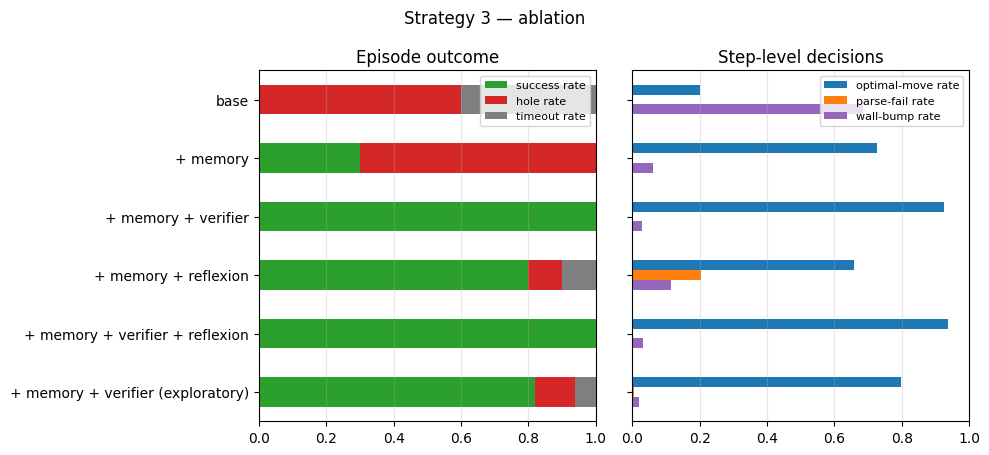

In [ ]:
summary = summary_table(runs)
summary["retries/step"] = [steps["retries"].mean() if "retries" in steps else 0.0 for _, steps in runs.values()]
summary["attempts/map"] = [eps["trial"].mean() if "trial" in eps else 1.0 for eps, _ in runs.values()]
first = trials[trials["trial"] == 1].groupby("run")["success"].mean()
summary["first-attempt success"] = [first.get(n, summary.loc[n, "success rate"]) for n in summary.index]
summary["reflection tokens"] = [eps.attrs.get("reflect_tokens", 0) for eps, _ in runs.values()]
display(summary)
plot_results(summary, "Strategy 3 — ablation", name="s3_ablation")

In [ ]:
# Reflexion: success by attempt and lessons written by the LLM
by_trial = trials.groupby(["run", "trial"]).agg(episodes_tried=("map", "count"), solved=("success", "sum"))
by_trial["cumulative success rate"] = by_trial.groupby(level="run")["solved"].cumsum() / (len(MAPS) * N_DET_REPEATS)
display(by_trial)
for _, l in lessons.iterrows():
    print(f"[{l['run']} | rep {l['rep']} | {l['map']} after trial {l['after_trial']}] {l['lesson']}")

episodes_tried  solved  \
run                             trial                           
+ memory + reflexion            1                  20       6   
                                2                  14       8   
                                3                   6       2   
+ memory + verifier + reflexion 1                  20      20   

                                       cumulative success rate  
run                             trial                           
+ memory + reflexion            1                          0.3  
                                2                          0.7  
                                3                          0.8  
+ memory + verifier + reflexion 1                          1.0

[+ memory + reflexion | rep 0 | default after trial 1.0] Avoid the hole on row 1, col 1, and head towards the right instead of moving down.
[+ memory + reflexion | rep 0 | rand1 after trial 1.0] Avoid the hole on row 1, col 0. Instead, head towards the solid ice on row 2, col 0.
[+ memory + reflexion | rep 0 | rand2 after trial 1.0] Avoid the hole on the top-left corner (row 1, col 1) and head directly towards the goal (row 3, col 3).
[+ memory + reflexion | rep 0 | rand4 after trial 1.0] Avoid moving into the hole on row 2, column 1. Instead, head towards the right to continue moving forward.
[+ memory + reflexion | rep 0 | rand5 after trial 1.0] Avoid moving into the hole on row 2, column 1, and instead head towards the goal by moving right to column 3.
[+ memory + reflexion | rep 0 | rand8 after trial 1.0] Avoid the hole on row 1, col 0. Instead, head towards the solid ice on row 2, col 0.
[+ memory + reflexion | rep 0 | rand9 after trial 1.0] Avoid the hole on row 1, col 0. Instead

In [ ]:
# Save results — the comparison with Strategies 1 and 2 is in Strategy_Comparison.ipynb
summary.assign(strategy="S3").to_csv("summary_s3.csv")
pd.concat([steps for _, steps in runs.values()]).to_csv("steps_s3.csv", index=False)
trials.to_csv("trials_s3.csv", index=False)
lessons.to_csv("lessons_s3.csv", index=False)
print("saved: summary_s3.csv, steps_s3.csv, trials_s3.csv, lessons_s3.csv")

saved: summary_s3.csv, steps_s3.csv, trials_s3.csv, lessons_s3.csv


## 9. Reasoning transcripts
Verifier messages appear as `[verifier] ...`.

In [ ]:
SHOW_RUN, SHOW_MAP = "+ memory + verifier", "default"
show_transcript(runs[SHOW_RUN][1], SHOW_MAP)

Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  A  F  F  F
r1  F  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 0, col 0, and the goal is on row 3, col 3. 

━━━ step 0 | (0, 0) → DOWN → (1, 0) (F) | 23 tokens ━━━
  Safe moves: DOWN, RIGHT
  Closer to G: RIGHT
  My choice: RIGHT
  ACTION: DOWN 

━━━ step 1 | (1, 0) → UP → (0, 0) (S) | 90 tokens ━━━
  Safe moves: DOWN
  Closer to G: (1,0) → (1,1)
  My choice: RIGHT
  ACTION: RIGHT
  [verifier] Careful! RIGHT takes you to row 1, col 1, and that's a hole. Pick a different move.
  Safe moves: DOWN
  Closer to G: (1,0) → (1,1)
  My choice: LEFT
  ACTION: LEFT
  [verifier] Hold on, LEFT would just push you against the edge and you wouldn't move. Pick something else.
  Safe moves: DOWN
  Closer to G: (1,0) → (1,1)
  My choice: UP
  ACTION: UP 

━━━ step 2 | (0, 0) → RIGHT → (0, 1) (F) | 23 tokens ━━━
  Safe moves: DOWN, RIGHT
  Closer to G: RIGHT
  My choice: RIGHT
  

In [ ]:
# Download the results (Colab only). Upload them to results/ in the repo for the comparison notebook.
import zipfile
try:
    from google.colab import files
except ImportError:
    files = None

with zipfile.ZipFile("experiment_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for filename in ['summary_s3.csv', 'steps_s3.csv', 'trials_s3.csv', 'lessons_s3.csv']:
        if os.path.exists(filename):
            z.write(filename)
    for root, _, filenames in os.walk("figures"):
        for filename in filenames:
            z.write(os.path.join(root, filename))
print("zip:", "experiment_results.zip")
if files is not None:
    files.download("experiment_results.zip")

zip: experiment_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>